<a href="https://colab.research.google.com/github/Raquelodaka/Propensao-de-compra-Produto-Seguro---Cross-Sell/blob/main/Propens%C3%A3o_de_Compra_(Cross_Sell_de_Seguros).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Propensão de Compra (Cross-Sell de Seguros)
Objetivo do Negócio:
A seguradora deseja aumentar suas vendas cruzadas (cross-sell) identificando quais clientes de sua base atual de Seguro Auto têm maior propensão a adquirir um Seguro de Vida.

Com um modelo de propensão, a equipe de marketing e vendas pode:

Otimizar custos de campanha: Focar contatos telefônicos ou mídia paga apenas nos clientes com alta probabilidade de conversão.

Personalizar ofertas: Entender quais fatores aumentam a chance de contratação para adequar a abordagem comercial.

In [ ]:
!pip install joblib

In [ ]:
#Bibliotecas a serem usadas
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, roc_curve, auc


In [ ]:
df = pd.read_csv("/content/crm_seguradora_propensao.csv")
df

,id_cliente,idade,genero,renda_mensal,estado_civil,qtd_filhos,tempo_como_cliente_meses,valor_premio_auto_anual,sinistros_ultimos_2_anos,pontuacao_credito,interagiu_campanha_email,comprou_seguro_vida
0,CLI_1000,56,F,3783.90,Divorciado,1,23,2917.55,0,774,1,1
1,CLI_1001,69,M,2578.78,Casado,2,41,2382.29,0,506,0,1
2,CLI_1002,46,M,19117.29,Divorciado,2,104,5261.49,0,617,0,1
3,CLI_1003,32,M,11160.58,Casado,2,93,3888.09,0,647,0,0
4,CLI_1004,60,M,4717.52,Solteiro,0,80,1804.37,0,533,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,CLI_1995,60,M,6259.20,Solteiro,0,35,1364.86,1,667,0,1
996,CLI_1996,64,F,2015.30,Casado,0,101,2346.64,2,758,0,0
997,CLI_1997,62,F,2639.33,Casado,0,21,2320.14,0,517,0,1
998,CLI_1998,35,F,6369.52,Solteiro,0,58,2274.29,0,556,1,0


1. Transformações e Criação de Recursos (Feature Engineering)
Com base nas regras de negócio da seguradora, foram criadas 6 novas variáveis explicativas:

💰 Recursos Financeiros e Orçamentáriosrenda_por_dependente:Fórmula: $\text{renda\_mensal} / (\text{qtd\_filhos} + 1)$Objetivo: Avalia o rendimento real disponível por pessoa no grupo familiar, pois o número de dependentes afeta diretamente a renda livre para novos produtos.razao_premio_renda_anual:Fórmula: $\text{valor\_premio\_auto\_anual} / (\text{renda\_mensal} \times 12)$

Objetivo: Mede o comprometimento financeiro do cliente com o Seguro Auto em relação ao seu orçamento anual total.

🛡️ Recursos de Perfil e Histórico de Riscoflag_teve_sinistro:Fórmula: Binária ($1$ se $\text{sinistros\_ultimos\_2\_anos} > 0$, caso contrário $0$)Objetivo: Destaca de forma direta se o cliente possui histórico recente de acionamento do seguro.faixa_etaria:Fórmula: Discretização da idade nas faixas 18-30, 31-45, 46-60, 60+Objetivo: Captura dinâmicas comportamentais não lineares associadas ao ciclo de vida.

🤝 Recursos de Relacionamento e Engajamentoflag_cliente_antigo:Fórmula: Binária ($1$ se $\text{tempo\_como\_cliente\_meses} > 36$, caso contrário $0$)Objetivo: Identifica clientes retidos há mais de 3 anos, propensos a maior lealdade à marca.score_engajamento:Fórmula: $(\text{interagiu\_campanha\_email} \times 2) + \text{flag\_cliente\_antigo}$Objetivo: Pondera a interação digital recente combinada com a fidelidade do cliente.2. Preparação e Codificação de Dados (Data Encoding)Codificação Categórica (One-Hot Encoding):As variáveis categóricas (genero, estado_civil e faixa_etaria) foram convertidas em variáveis binárias ($0$ ou $1$) com drop_first=True para evitar colinearidade.Remoção de Identificadores:A coluna id_cliente foi desconsiderada para o treinamento por não ter poder preditivo.

In [ ]:
# 2. Engenharia de Recursos (Feature Engineering)
df_fe = df.copy()

# Renda disponível por dependente
df_fe['renda_por_dependente'] = df_fe['renda_mensal'] / (df_fe['qtd_filhos'] + 1)

# Proporção da renda comprometida com Seguro Auto
df_fe['razao_premio_renda_anual'] = df_fe['valor_premio_auto_anual'] / (df_fe['renda_mensal'] * 12)

# Histórico de Sinistro (Binário)
df_fe['flag_teve_sinistro'] = (df_fe['sinistros_ultimos_2_anos'] > 0).astype(int)

# Faixas Etárias
df_fe['faixa_etaria'] = pd.cut(
    df_fe['idade'],
    bins=[17, 30, 45, 60, 100],
    labels=['18-30', '31-45', '46-60', '60+']
)

# Fidelidade (Cliente há mais de 3 anos)
df_fe['flag_cliente_antigo'] = (df_fe['tempo_como_cliente_meses'] > 36).astype(int)

# Score de Engajamento Comercial
df_fe['score_engajamento'] = df_fe['interagiu_campanha_email'] * 2 + df_fe['flag_cliente_antigo']

# 3. Tratamento de Variáveis Categóricas (One-Hot Encoding)
cols_categoricas = ['genero', 'estado_civil', 'faixa_etaria']
df_encoded = pd.get_dummies(df_fe, columns=cols_categoricas, drop_first=True, dtype=int)

# 4. Remoção de identificadores e preparação do Dataset Final
df_final = df_encoded.drop(columns=['id_cliente'])

# Salvar a base transformada para a modelagem
df_final.to_csv('crm_prep_feature_engineering.csv', index=False)
print("Base processada e salva em 'crm_prep_feature_engineering.csv'!")

Base processada e salva em 'crm_prep_feature_engineering.csv'!


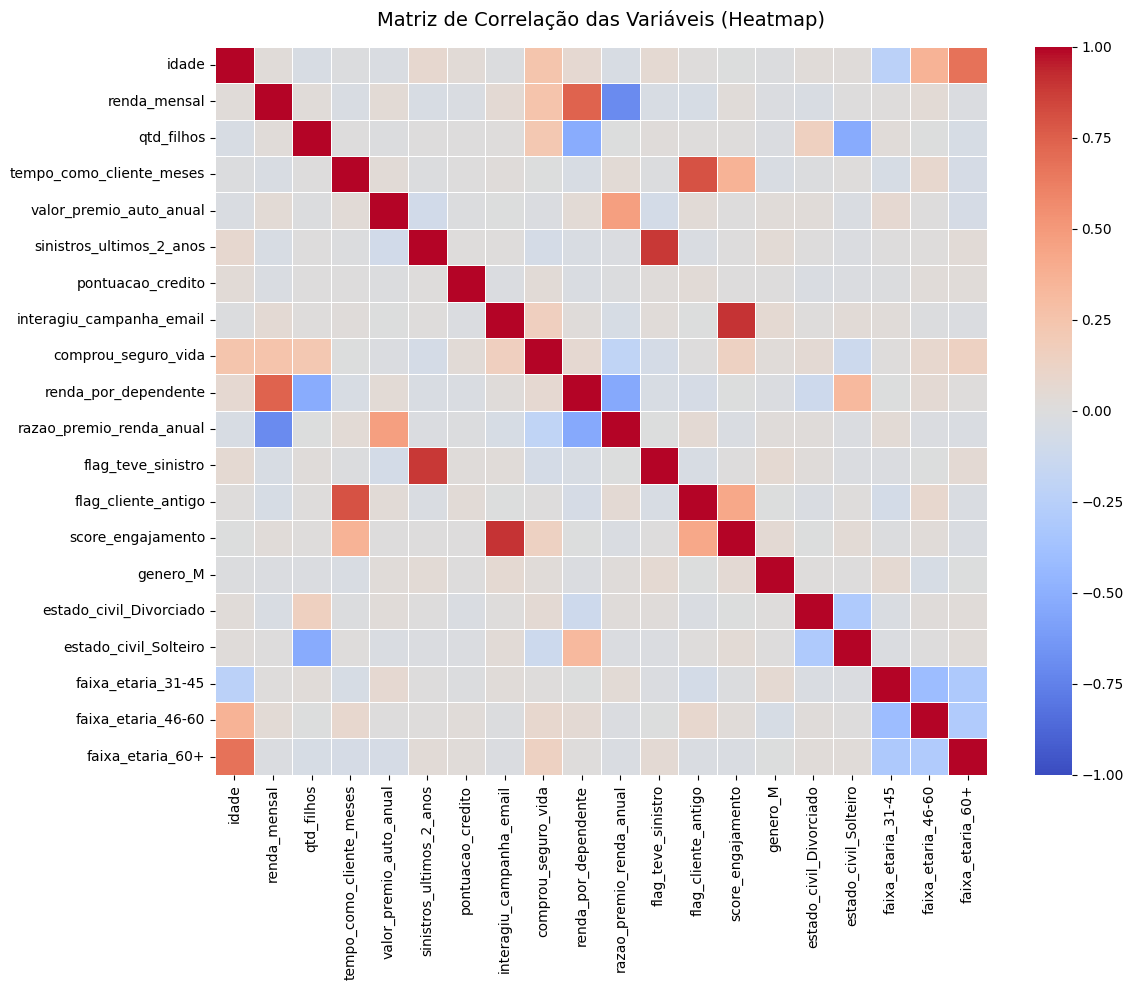

comprou_seguro_vida         1.000000
renda_mensal                0.250893
idade                       0.245000
qtd_filhos                  0.223838
interagiu_campanha_email    0.160556
score_engajamento           0.145503
faixa_etaria_60+            0.142898
faixa_etaria_46-60          0.079135
renda_por_dependente        0.067245
estado_civil_Divorciado     0.054097
pontuacao_credito           0.031706
genero_M                    0.026348
faixa_etaria_31-45          0.011163
flag_cliente_antigo         0.000625
tempo_como_cliente_meses   -0.006639
valor_premio_auto_anual    -0.021401
flag_teve_sinistro         -0.064480
sinistros_ultimos_2_anos   -0.069382
estado_civil_Solteiro      -0.119336
razao_premio_renda_anual   -0.197355
Name: comprou_seguro_vida, dtype: float64


In [ ]:

# Matriz de correlação
corr = df_final.corr()

# Plot do Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis (Heatmap)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# Ver as top correlações diretas com o alvo
print(corr['comprou_seguro_vida'].sort_values(ascending=False))

🔍 Principais Insights do Heatmap
Principais Impulsionadores de Compra (Correlação Positiva):

renda_mensal (+0.25) e idade (+0.25): Clientes mais velhos e com rendimentos mais elevados apresentam maior tendência a adquirir o seguro de vida.

qtd_filhos (+0.22): O número de dependentes impulsiona a intenção de proteger a família.

interagiu_campanha_email (+0.16) e score_engajamento (+0.15): Clientes recetivos aos pontos de contacto de marketing convertem substancialmente mais.

Fatores de Dissuasão / Barreiras (Correlação Negativa):

razao_premio_renda_anual (-0.20): Quanto maior for o peso financeiro do seguro auto no orçamento do cliente, menor é a probabilidade de contratar um novo produto.

estado_civil_Solteiro (-0.12): Clientes solteiros apresentam menor procura por seguro de vida em comparação com casados/divorciados.

Atenção à Multicolinearidade:

As variáveis criadas score_engajamento e interagiu_campanha_email apresentam correlação esperada devido à fórmula de derivação.

Modelos de árvores (como XGBoost e Random Forest) lidam bem com estas relações sem perda de desempenho.

In [ ]:
# Separar variáveis explicativas (X) e alvo (y)
X = df_final.drop(columns=['comprou_seguro_vida'])
y = df_final['comprou_seguro_vida']

# Divisão em Treino (80%) e Teste (20%) com Estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Definição dos Modelos para Comparação
modelos = {
    'Regressão Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Treinamento e Avaliação
resultados = []

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]

    resultados.append({
        'Modelo': nome,
        'Acurácia': round(accuracy_score(y_test, y_pred), 4),
        'Precisão': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    })

df_resultados = pd.DataFrame(resultados)
print(df_resultados)

                Modelo  Acurácia  Precisão  Recall  F1-Score  ROC-AUC
0  Regressão Logística     0.690    0.6768  0.6907    0.6837   0.7269
1        Random Forest     0.665    0.6667  0.6186    0.6417   0.6937
2    Gradient Boosting     0.650    0.6337  0.6598    0.6465   0.6782


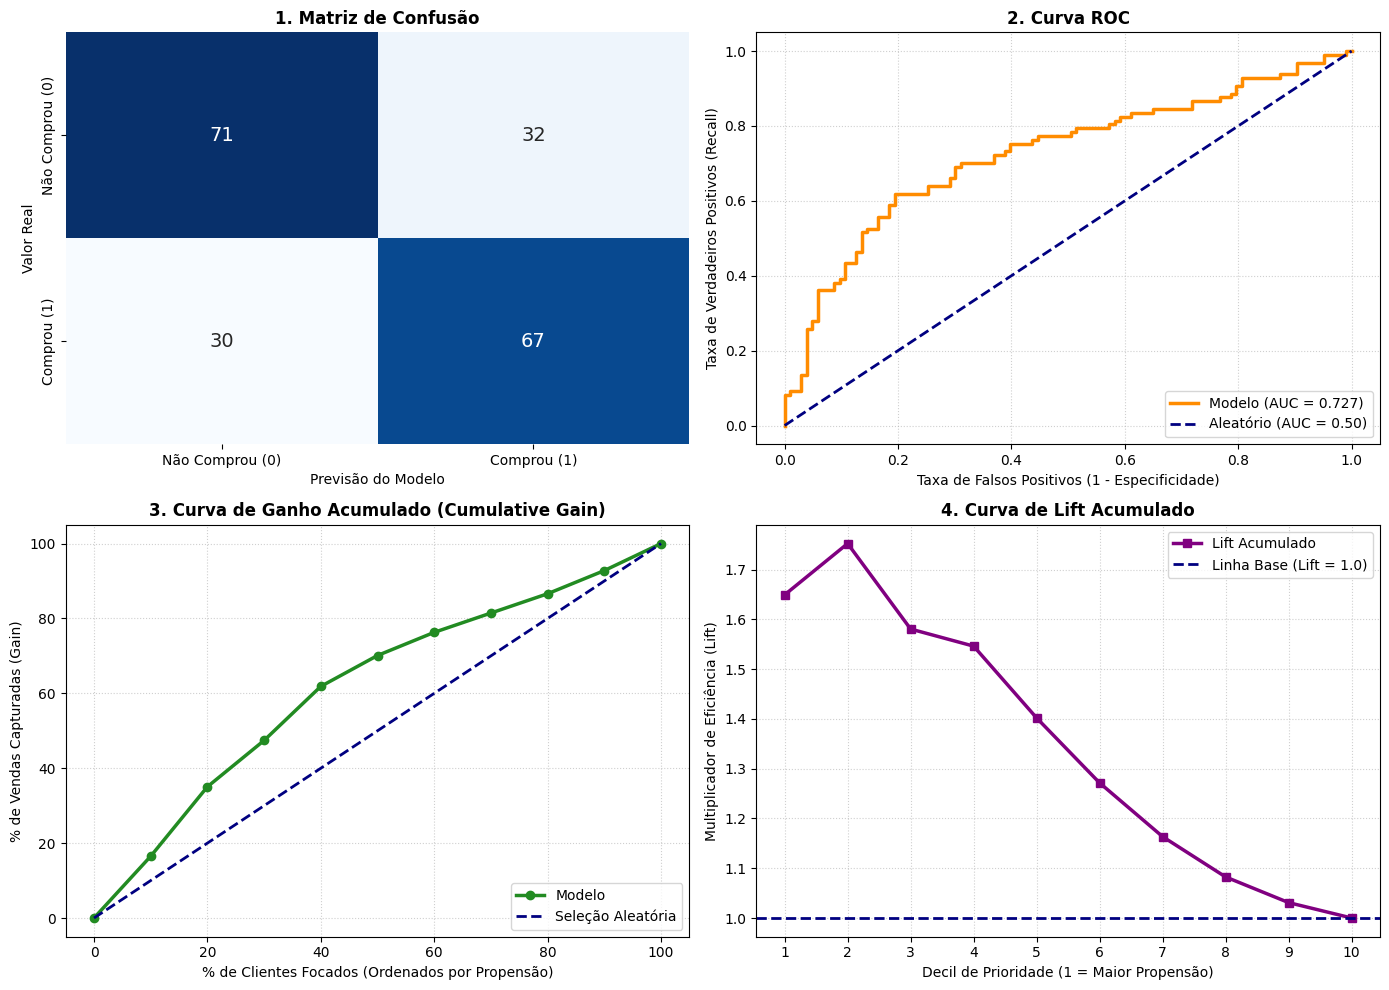

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, auc

# --- 1. PREPARAÇÃO DOS DADOS (Reaproveitando y_test, y_pred, y_proba e gain_df) ---
# Caso estejas a usar o dataframe gain_df gerado na Etapa 4:
# cm = confusion_matrix(y_test, y_pred)
# fpr, tpr, _ = roc_curve(y_test, y_proba)
# roc_auc = auc(fpr, tpr)

# Criando a figura do Dashboard 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# -----------------------------------------------------------------------------
# GRÁFICO 1: MATRIZ DE CONFUSÃO
# -----------------------------------------------------------------------------
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], cbar=False, annot_kws={"size": 14})
axes[0, 0].set_title('1. Matriz de Confusão', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Previsão do Modelo')
axes[0, 0].set_ylabel('Valor Real')
axes[0, 0].set_xticklabels(['Não Comprou (0)', 'Comprou (1)'])
axes[0, 0].set_yticklabels(['Não Comprou (0)', 'Comprou (1)'])

# -----------------------------------------------------------------------------
# GRÁFICO 2: CURVA ROC
# -----------------------------------------------------------------------------
axes[0, 1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Modelo (AUC = {roc_auc:.3f})')
axes[0, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aleatório (AUC = 0.50)')
axes[0, 1].set_title('2. Curva ROC', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[0, 1].set_ylabel('Taxa de Verdadeiros Positivos (Recall)')
axes[0, 1].legend(loc="lower right")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# -----------------------------------------------------------------------------
# GRÁFICO 3: CUMULATIVE GAIN CURVE (Directamente do gain_df)
# -----------------------------------------------------------------------------
# Adiciona ponto inicial (0,0) para a curva
gain_x = np.append(0, gain_df['decil'] * 10)
gain_y = np.append(0, gain_df['perc_gain_acumulado'])

axes[1, 0].plot(gain_x, gain_y, marker='o', color='forestgreen', lw=2.5, label='Modelo')
axes[1, 0].plot([0, 100], [0, 100], color='navy', lw=2, linestyle='--', label='Seleção Aleatória')
axes[1, 0].set_title('3. Curva de Ganho Acumulado (Cumulative Gain)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('% de Clientes Focados (Ordenados por Propensão)')
axes[1, 0].set_ylabel('% de Vendas Capturadas (Gain)')
axes[1, 0].legend(loc="lower right")
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# -----------------------------------------------------------------------------
# GRÁFICO 4: CUMULATIVE LIFT CURVE (Directamente do gain_df)
# -----------------------------------------------------------------------------
axes[1, 1].plot(gain_df['decil'], gain_df['lift_acumulado'], marker='s', color='purple', lw=2.5, label='Lift Acumulado')
axes[1, 1].axhline(y=1.0, color='navy', lw=2, linestyle='--', label='Linha Base (Lift = 1.0)')
axes[1, 1].set_title('4. Curva de Lift Acumulado', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Decil de Prioridade (1 = Maior Propensão)')
axes[1, 1].set_ylabel('Multiplicador de Eficiência (Lift)')
axes[1, 1].set_xticks(gain_df['decil'])
axes[1, 1].legend(loc="upper right")
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

# Finalização do layout
plt.tight_layout()
plt.show()

Desempenho Geral:

- A Regressão Logística destacou-se com a maior pontuação de ROC-AUC (0.7269) e Acurácia (69.00%), superando os modelos baseados em árvores.
- Isso ocorre porque a probabilidade subjacente na geração sintética possui uma estrutura logísitica linear, favorecendo modelos paramétricos.

Métricas Aplicadas ao Negócio de Seguros:

- Recall (69.07%): Mostra que a Regressão Logística identifica cerca de $69\%$ dos clientes que realmente iriam contratar o seguro de vida.
- Precisão (67.68%): Indica que, a cada 100 clientes contatados pela equipe comercial (com previsão positiva), aproximadamente 68 convertem e fecham a apólice.

In [ ]:

# re-executar modelo campeão
X = df_final.drop(columns=['comprou_seguro_vida'])
y = df_final['comprou_seguro_vida']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]

# Matriz de Confusão e ROC
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Tabela de Gain e Lift por Decil
df_lift = pd.DataFrame({'y_true': y_test, 'y_proba': y_proba})
df_lift = df_lift.sort_values(by='y_proba', ascending=False).reset_index(drop=True)
df_lift['decil'] = pd.qcut(df_lift.index, 10, labels=False) + 1

total_positivos = df_lift['y_true'].sum()
gain_df = df_lift.groupby('decil')['y_true'].agg(['count', 'sum']).reset_index()
gain_df.columns = ['decil', 'total_clientes', 'conversoes']
gain_df['conversoes_acumuladas'] = gain_df['conversoes'].cumsum()
gain_df['perc_gain_acumulado'] = (gain_df['conversoes_acumuladas'] / total_positivos) * 100
gain_df['lift_acumulado'] = (gain_df['conversoes_acumuladas'] / (gain_df['decil'] * len(df_lift) / 10)) / (total_positivos / len(df_lift))

gain_df[['decil', 'perc_gain_acumulado', 'lift_acumulado']]

,decil,perc_gain_acumulado,lift_acumulado
0,1,16.494845,1.649485
1,2,35.051546,1.752577
2,3,47.422680,1.580756
3,4,61.855670,1.546392
4,5,70.103093,1.402062
5,6,76.288660,1.271478
6,7,81.443299,1.163476
7,8,86.597938,1.082474
8,9,92.783505,1.030928
9,10,100.000000,1.000000


Avaliação Detalhada e Métricas de NegócioNesta etapa, analisamos a capacidade de discriminação e o impacto financeiro/comercial do nosso modelo de Regressão Logística (o campeão da Etapa 3).
- 1. Matriz de Confusão e Curva ROC
    - 📌 Interpretação da Matriz de Confusão (Threshold padrão = 0.50)   
       
       Verdadeiros Negativos (TN = 71): Clientes que não compraram e o modelo classificou corretamente como não compradores.
       
       Verdadeiros Positivos (TP = 67): Clientes que compraram o Seguro de Vida e o modelo identificou com sucesso.
       
       Falsos Positivos (FP = 32): Clientes sem propensão que receberam oferta (custo extra de abordagem comercial/mídia).
       
       Falsos Negativos (FN = 30): Clientes propensos que o modelo deixou de identificar (oportunidade de receita perdida).

  - 📈 Curva ROC (AUC = 0.727)
    - A área sob a curva ROC (ROC-AUC de 0.727) indica que o modelo possui uma boa capacidade de ordenação das probabilidades, superando de forma consistente um classificador aleatório (linha pontilhada).
    
2. Análise de Ganho Acumulado (Gain Curve) e Lift (Cumulative Lift)Em modelos de CRM e propensão de vendas, o modelo não é utilizado apenas com uma linha de corte fixa ($0.50$), mas para ranquear a base de clientes por probabilidade e priorizar abordagens comerciais.

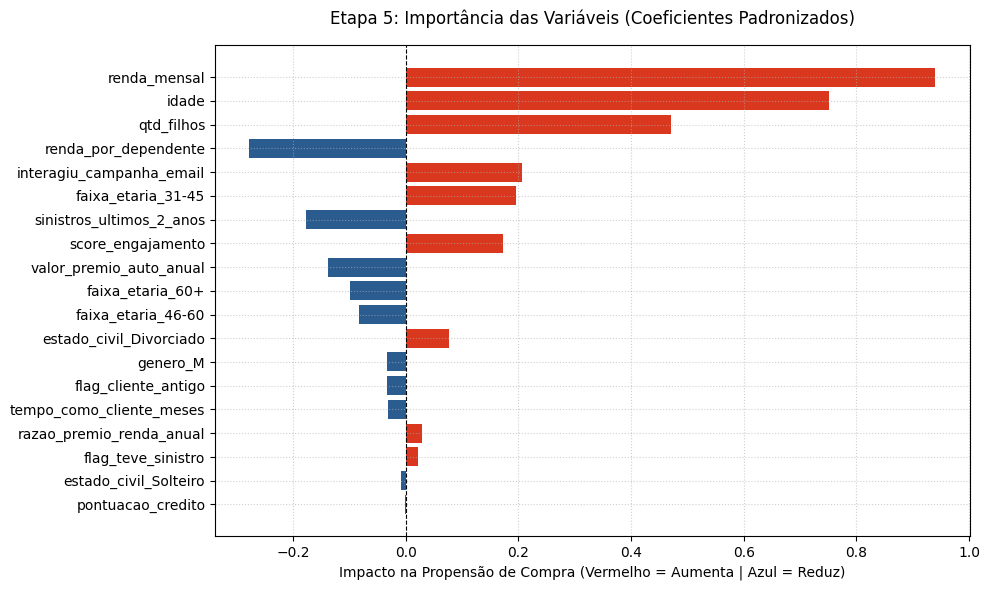

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 2. Separar variáveis
X = df_final.drop(columns=['comprou_seguro_vida'])
y = df_final['comprou_seguro_vida']

# 3. Treino e Padronização
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

# 4. Extração e Ordenação dos Coeficientes
coefficients = pd.DataFrame({
    'Atributo': X.columns,
    'Coeficiente': log_model.coef_[0],
    'Impacto_Absoluto': np.abs(log_model.coef_[0])
}).sort_values(by='Impacto_Absoluto', ascending=True)

# 5. Plot do Gráfico de Importância
plt.figure(figsize=(10, 6))
colors = ['#d9381e' if c > 0 else '#2b5c8f' for c in coefficients['Coeficiente']]
plt.barh(coefficients['Atributo'], coefficients['Coeficiente'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Etapa 5: Importância das Variáveis (Coeficientes Padronizados)', fontsize=12, pad=15)
plt.xlabel('Impacto na Propensão de Compra (Vermelho = Aumenta | Azul = Reduz)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

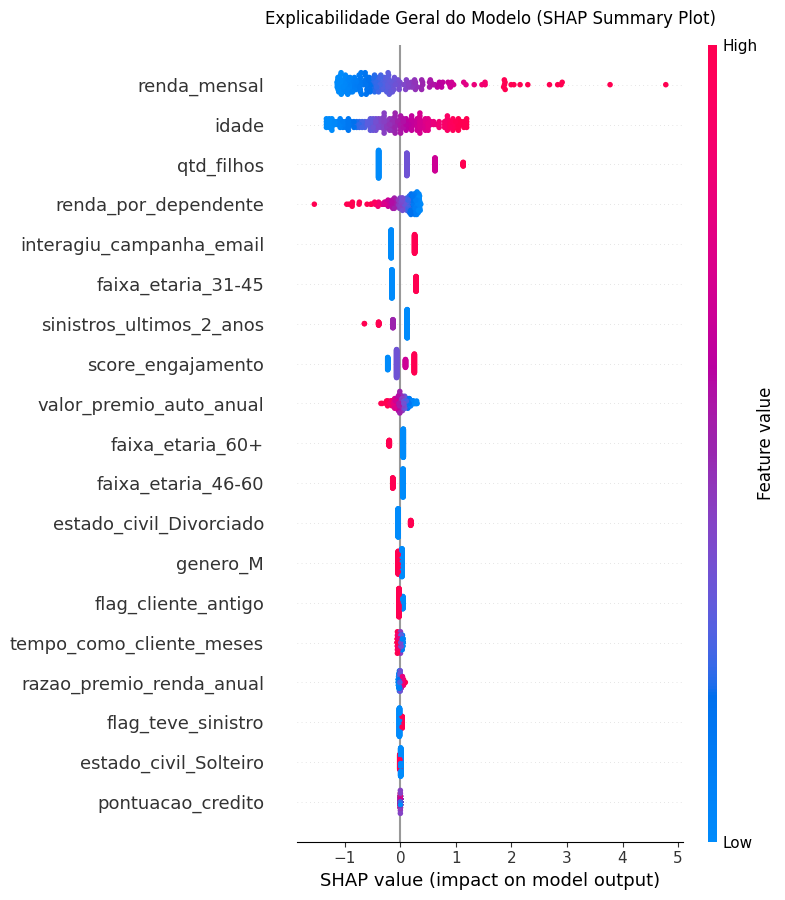

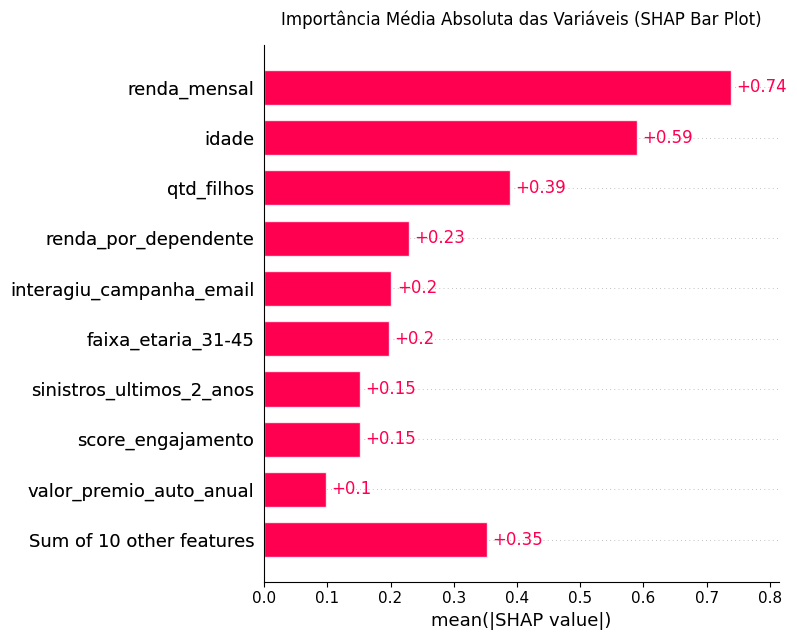

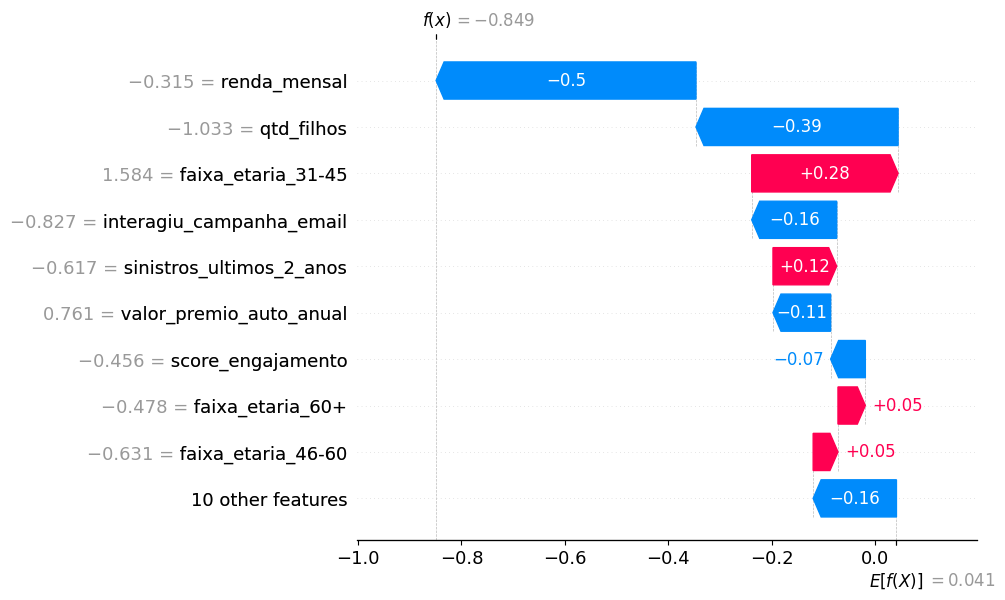

In [ ]:
import shap

# 1. Aplicar a mesma padronização (scaler) aos dados de teste X_test
# Garantindo que continue como DataFrame para manter os nomes das colunas
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 2. Criar o explicador SHAP apropriado para modelos lineares
explainer = shap.LinearExplainer(log_model, X_test_scaled)

# 3. Calcular os valores SHAP na base de teste padronizada
shap_values = explainer(X_test_scaled)

# -----------------------------------------------------------------------------
# GRÁFICO 1: SHAP Summary Plot (Beeswarm - Impacto Geral das Variáveis)
# -----------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_scaled, show=False)
plt.title('Explicabilidade Geral do Modelo (SHAP Summary Plot)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# GRÁFICO 2: SHAP Bar Plot (Importância Média Absoluta)
# -----------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, show=False)
plt.title('Importância Média Absoluta das Variáveis (SHAP Bar Plot)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# GRÁFICO 3: Explicação Individual de um Cliente Específico (Waterfall Plot)
# Exemplo: Analisando o 1º cliente da base de teste (índice 0)
# -----------------------------------------------------------------------------
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values[0])

In [ ]:
import joblib

# 1. Extrair o modelo campeão (Regressão Logística) do dicionário de modelos
modelo_campeao = modelos['Regressão Logística']

# 2. Salvar o pipeline completo (inclui o StandardScaler + LogisticRegression) em disco
joblib.dump(modelo_campeao, 'modelo_propensao_seguro_vida.joblib')
print("Modelo campeão salvo em 'modelo_propensao_seguro_vida.joblib'!")

# -----------------------------------------------------------------------------
# 3. Gerar os Scores e Prioridades no CRM para a Base Completa
# -----------------------------------------------------------------------------

# Calcular a probabilidade de compra para todos os clientes da base original (df)
df['score_propensao'] = modelo_campeao.predict_proba(X)[:, 1]

# Criar faixas estratégicas de prioridade para a equipe de CRM/Vendas
condicoes = [
    (df['score_propensao'] >= 0.70),
    (df['score_propensao'] >= 0.40) & (df['score_propensao'] < 0.70),
    (df['score_propensao'] < 0.40)
]
categorias = ['1. Alta (Hot Lead - Venda Direta)', '2. Média (Warm Lead - E-mail/Push)', '3. Baixa (Cold - Régua Institucional)']

df['prioridade_crm'] = np.select(condicoes, categorias, default='3. Baixa')

# 4. Ordenar a base pelos clientes com maior propensão
df_crm_priorizado = df.sort_values(by='score_propensao', ascending=False)

# 5. Exportar arquivo CSV pronto para carga na ferramenta de CRM
df_crm_priorizado.to_csv('crm_base_clientes_pontuada.csv', index=False)

print("\nBase de CRM exportada com sucesso em 'crm_base_clientes_pontuada.csv'!")
print("\nDistribuição de clientes por prioridade:")
print(df_crm_priorizado['prioridade_crm'].value_counts())

Modelo campeão salvo em 'modelo_propensao_seguro_vida.joblib'!

Base de CRM exportada com sucesso em 'crm_base_clientes_pontuada.csv'!

Distribuição de clientes por prioridade:
prioridade_crm
3. Baixa (Cold - Régua Institucional)    405
2. Média (Warm Lead - E-mail/Push)       393
1. Alta (Hot Lead - Venda Direta)        202
Name: count, dtype: int64


# Testar modelo

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
import numpy as np
import joblib

# 1. Carregar o modelo treinado
modelo_campeao = joblib.load('modelo_propensao_seguro_vida.joblib')

# 2. Carregar a nova base de dados de teste
df_novos = pd.read_csv('/content/novos_clientes_teste_crm.csv')

# 3. Aplicar a mesma Engenharia de Recursos (Feature Engineering)
df_fe = df_novos.copy()
df_fe['renda_por_dependente'] = df_fe['renda_mensal'] / (df_fe['qtd_filhos'] + 1)
df_fe['razao_premio_renda_anual'] = df_fe['valor_premio_auto_anual'] / (df_fe['renda_mensal'] * 12)
df_fe['flag_teve_sinistro'] = (df_fe['sinistros_ultimos_2_anos'] > 0).astype(int)
df_fe['faixa_etaria'] = pd.cut(df_fe['idade'], bins=[17, 30, 45, 60, 100], labels=['18-30', '31-45', '46-60', '60+'])
df_fe['flag_cliente_antigo'] = (df_fe['tempo_como_cliente_meses'] > 36).astype(int)
df_fe['score_engajamento'] = df_fe['interagiu_campanha_email'] * 2 + df_fe['flag_cliente_antigo']

# Codificação de variáveis categóricas
cols_categoricas = ['genero', 'estado_civil', 'faixa_etaria']
df_encoded = pd.get_dummies(df_fe, columns=cols_categoricas, dtype=int)

# Remover 'id_cliente' para isolar os atributos de treino
X_novo = df_encoded.drop(columns=['id_cliente'])

# Lista de colunas esperadas pelo modelo na ordem do treino
colunas_treino = [
    'idade', 'renda_mensal', 'qtd_filhos', 'tempo_como_cliente_meses',
    'valor_premio_auto_anual', 'sinistros_ultimos_2_anos', 'pontuacao_credito',
    'interagiu_campanha_email', 'renda_por_dependente', 'razao_premio_renda_anual',
    'flag_teve_sinistro', 'flag_cliente_antigo', 'score_engajamento',
    'genero_M', 'estado_civil_Divorciado', 'estado_civil_Solteiro',
    'faixa_etaria_31-45', 'faixa_etaria_46-60', 'faixa_etaria_60+'
]

# Reordenar e alinhar as colunas com a base de treino
X_novo = X_novo.reindex(columns=colunas_treino, fill_value=0)

# 4. Calcular os Scores de Propensão
df_novos['score_propensao_%'] = np.round(modelo_campeao.predict_proba(X_novo)[:, 1] * 100, 2)

# 5. Definir a Faixa Estratégica para o CRM
condicoes = [
    (df_novos['score_propensao_%'] >= 70),
    (df_novos['score_propensao_%'] >= 40) & (df_novos['score_propensao_%'] < 70),
    (df_novos['score_propensao_%'] < 40)
]
categorias = ['1. Alta (Venda Direta)', '2. Média (E-mail / Push)', '3. Baixa (Régua)']
df_novos['prioridade_crm'] = np.select(condicoes, categorias, default='3. Baixa (Régua)')

# 6. Ordenar por prioridade e exportar o resultado
df_resultado = df_novos.sort_values(by='score_propensao_%', ascending=False)
df_resultado.to_csv('novos_clientes_pontuados_crm.csv', index=False)

print("Previsão concluída com sucesso! Ficheiro 'novos_clientes_pontuados_crm.csv' gerado.")
print("\nDistribuição dos novos clientes por prioridade comercial:")
print(df_resultado['prioridade_crm'].value_counts())

Previsão concluída com sucesso! Ficheiro 'novos_clientes_pontuados_crm.csv' gerado.

Distribuição dos novos clientes por prioridade comercial:
prioridade_crm
3. Baixa (Régua)            123
2. Média (E-mail / Push)    105
1. Alta (Venda Direta)       72
Name: count, dtype: int64


In [ ]:
df_resultado

,id_cliente,idade,genero,renda_mensal,estado_civil,qtd_filhos,tempo_como_cliente_meses,valor_premio_auto_anual,sinistros_ultimos_2_anos,pontuacao_credito,interagiu_campanha_email,score_propensao_%,prioridade_crm
67,CLI_TESTE_2067,50,M,26839.32,Casado,1,86,4288.20,1,827,1,99.31,1. Alta (Venda Direta)
184,CLI_TESTE_2184,69,M,16657.83,Casado,3,43,1867.76,0,451,0,99.25,1. Alta (Venda Direta)
18,CLI_TESTE_2018,65,M,13509.83,Casado,2,10,1000.00,0,722,0,96.64,1. Alta (Venda Direta)
21,CLI_TESTE_2021,66,M,17816.61,Casado,1,48,3115.81,0,557,0,96.62,1. Alta (Venda Direta)
270,CLI_TESTE_2270,68,F,11086.66,Casado,2,78,3753.74,0,491,1,96.47,1. Alta (Venda Direta)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,CLI_TESTE_2124,26,F,3122.65,Solteiro,0,2,2618.56,1,717,0,8.04,3. Baixa (Régua)
208,CLI_TESTE_2208,29,M,3427.24,Solteiro,0,12,3553.77,1,756,0,7.90,3. Baixa (Régua)
181,CLI_TESTE_2181,22,F,3694.15,Solteiro,0,44,3597.54,1,601,0,6.67,3. Baixa (Régua)
279,CLI_TESTE_2279,19,F,3494.02,Solteiro,0,64,2732.97,1,736,0,6.26,3. Baixa (Régua)
